In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
print("Dataset Shape:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Dataset Shape: (442, 10)


In [2]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

lr = LinearRegression()
lr.fit(X_train, y_train)

ridge = Ridge()
lasso = Lasso(max_iter=10000)

In [3]:
from sklearn.model_selection import GridSearchCV

ridge_params = {
    'alpha': [0.01, 0.1, 1, 10, 100]
}

ridge_cv = GridSearchCV(
    ridge, ridge_params, cv=5, scoring='r2'
)

ridge_cv.fit(X_train, y_train)

lasso_params = {
    'alpha': [0.001, 0.01, 0.1, 1, 10]
}

lasso_cv = GridSearchCV(
    lasso, lasso_params, cv=5, scoring='r2'
)

lasso_cv.fit(X_train, y_train)
print("Lasso model trained successfully.")

Lasso model trained successfully.


In [4]:
from sklearn.metrics import mean_squared_error, r2_score

lr_pred = lr.predict(X_test)
ridge_pred = ridge_cv.best_estimator_.predict(X_test)
lasso_pred = lasso_cv.best_estimator_.predict(X_test)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Lasso Regression"],
    "Best Alpha": [
        "-",
        ridge_cv.best_params_['alpha'],
        lasso_cv.best_params_['alpha']
    ],
    "MSE": [
        mean_squared_error(y_test, lr_pred),
        mean_squared_error(y_test, ridge_pred),
        mean_squared_error(y_test, lasso_pred)
    ],
    "R2 Score": [
        r2_score(y_test, lr_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred)
    ]
})

print(results)

               Model Best Alpha          MSE  R2 Score
0  Linear Regression          -  2900.193628  0.452603
1   Ridge Regression         10  2875.778718  0.457211
2   Lasso Regression          1  2824.568094  0.466877


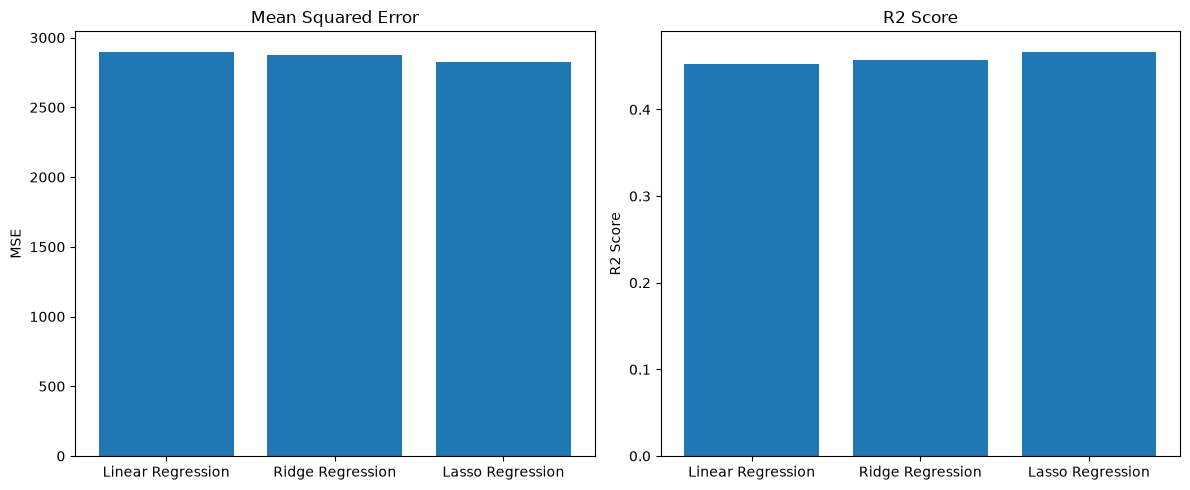

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].bar(results["Model"], results["MSE"])
ax[0].set_title("Mean Squared Error")
ax[0].set_ylabel("MSE")

ax[1].bar(results["Model"], results["R2 Score"])
ax[1].set_title("R2 Score")
ax[1].set_ylabel("R2 Score")

plt.tight_layout()
plt.show()